In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## loss-landscape

**Figure 1: Training loss around the trained model along two random directions in weight space.** The trained model sits at (0, 0); contour lines mark the colorbar levels. The model lies in a wide, flat basin: within a distance of 0.4 of it the loss stays below 0.87, against 0.08 at the solution and up to 4.21 at the edges.

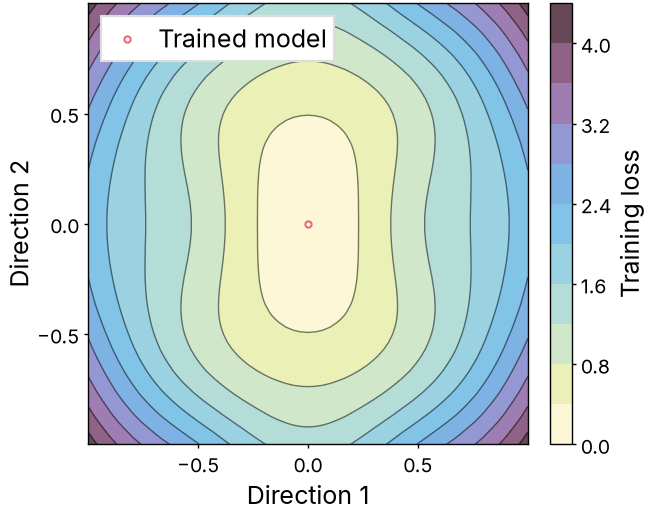

In [2]:
with open("../loss-landscape.json") as f:
    data = json.load(f)
alpha, beta, loss = np.array(data["alpha"]), np.array(data["beta"]), np.array(data["loss"])

fig, ax = plt.subplots(figsize=(3.25, 3))
cs = ax.contourf(alpha, beta, loss, levels=10)
ax.contour(alpha, beta, loss, levels=cs.levels, colors="black", linewidths=0.5, alpha=0.5)
fig.colorbar(cs, ax=ax, label="Training loss")
ax.plot(0, 0, "o", color=colors["ours"], label="Trained model")
ax.grid(False)
ax.set_xticks([-0.5, 0, 0.5])
ax.set_yticks([-0.5, 0, 0.5])
ax.set_xlabel("Direction 1")
ax.set_ylabel("Direction 2")
ax.legend(loc="upper left")

fit_height(fig, ax, aspect=1.0)
fig.savefig("loss-landscape.pdf")
fig.savefig("loss-landscape.png")
plt.show()